# 01 - Data preparation and exploratory analysis

**Owner:** Joseph Barron - CSC 7333 Group 6

The FERPlus data is already converted to NumPy arrays (both 48×48 and 224×224) and is grayscale. We:

1. verify that the files are consistent.
2. analyze the class distribution and discuss the reasons for Disgust and Contempt being excluded.
3. analyze the images (examples, average images, pixel values and image copies).
4. determine class weights which are used by all models to account for the class imbalance.

In [1]:
import hashlib
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Folders can be accessed whether the notebook is opened from the root of the repository or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
FIG = RESULTS_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SPLITS = ["Train", "Valid", "Test"]
ALL_CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Disgust", "Fear", "Contempt"]
DROPPED = ["Disgust", "Contempt"]
CLASSES = [c for c in ALL_CLASSES if c not in DROPPED]
SEED = 42

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(SEED)

In [2]:
def load_labels(split):
    # Class names are unchanged from what was provided. All 8 classes are still included.
    return np.load(DATA_DIR / f"FER2013{split}_labels.npy")


def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels

## 1. File check

Each split has 48×48, 224×224 and label data. The image and label data must have the same number of samples.

In [3]:
rows = []
for split in SPLITS:
    labels = load_labels(split)
    for size in (48, 224):
        path = DATA_DIR / f"FER2013{split}_{size}_images.npy"
        images = np.load(path, mmap_mode="r")
        rows.append({"split": split, "size": size, "shape": images.shape, "dtype": str(images.dtype),
                     "labels": len(labels), "match": len(images) == len(labels),
                     "MB": round(path.stat().st_size / 1e6, 1)})
pd.DataFrame(rows)

,split,size,shape,dtype,labels,match,MB
0,Train,48,"(25001, 48, 48)",uint8,25001,True,57.6
1,Train,224,"(25001, 224, 224)",uint8,25001,True,1254.5
2,Valid,48,"(3180, 48, 48)",uint8,3180,True,7.3
3,Valid,224,"(3180, 224, 224)",uint8,3180,True,159.6
4,Test,48,"(3131, 48, 48)",uint8,3131,True,7.2
5,Test,224,"(3131, 224, 224)",uint8,3131,True,157.1


## 2. Class distribution (all 8 original classes)

FERPlus relabeled the FER2013 data. There are 10 raters per image and the label corresponds to the most common rater choice.

In [4]:
raw_counts = pd.DataFrame({split: pd.Series(load_labels(split)).value_counts() for split in SPLITS})
raw_counts = raw_counts.loc[ALL_CLASSES]
raw_counts["Total"] = raw_counts.sum(axis=1)
raw_counts.loc["Total"] = raw_counts.sum()
raw_counts["% of total"] = (100 * raw_counts["Total"] / raw_counts.loc["Total", "Total"]).round(2)
raw_counts

,Train,Valid,Test,Total,% of total
Neutral,8740,1175,1081,10996,35.12
Happiness,7304,865,891,9060,28.93
Surprise,3125,413,400,3938,12.58
Sadness,3046,344,384,3774,12.05
Anger,2056,286,266,2608,8.33
Disgust,104,24,15,143,0.46
Fear,512,57,81,650,2.08
Contempt,114,16,13,143,0.46
Total,25001,3180,3131,31312,100.00


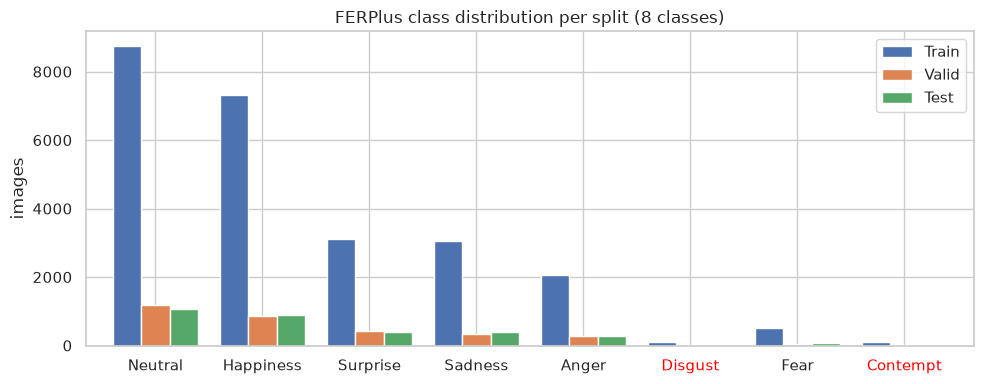

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_df = raw_counts.drop(index="Total")[list(SPLITS)]
plot_df.plot.bar(ax=ax, width=0.8)
ax.set_ylabel("images")
ax.set_title("FERPlus class distribution per split (8 classes)")
for name in DROPPED:
    ax.get_xticklabels()[ALL_CLASSES.index(name)].set_color("red")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(FIG / "class_distribution_8.png", dpi=150)
plt.show()

**Why Disgust and Contempt are excluded.** Between them, these make up less than 1% of data (around 140 images each across all splits). The test data only contains 15 Disgust and 13 Contempt images. Therefore, a single prediction changes their F1 score by several points. As we use a macro F1 to select our best performing model, this will largely reflect random noise. Analysis of the FERPlus labeling process also revealed that raters tend to be less consistent in their labeling for these two classes, and so their labels are less trustworthy. We therefore retain the other 6 classes.

In [6]:
data = {split: load_split(split, size=48) for split in SPLITS}

counts = pd.DataFrame({split: np.bincount(y, minlength=len(CLASSES)) for split, (_, y) in data.items()}, index=CLASSES)
counts["Total"] = counts.sum(axis=1)
counts.loc["Total"] = counts.sum()
print("removed images:", int(raw_counts.loc["Total", "Total"] - counts.loc["Total", "Total"]))
counts

removed images: 286


,Train,Valid,Test,Total
Neutral,8740,1175,1081,10996
Happiness,7304,865,891,9060
Surprise,3125,413,400,3938
Sadness,3046,344,384,3774
Anger,2056,286,266,2608
Fear,512,57,81,650
Total,24783,3140,3103,31026


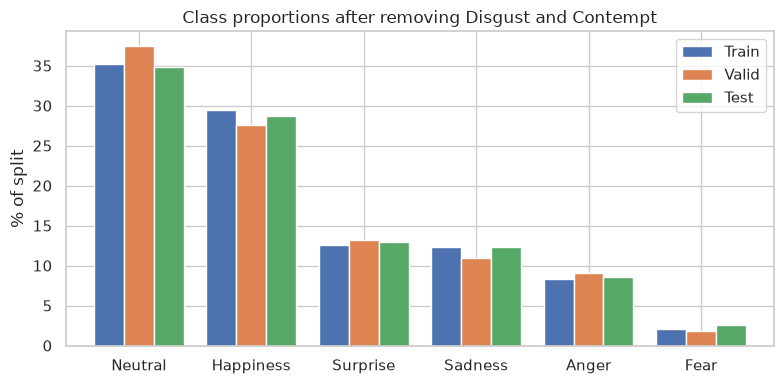

imbalance ratio (largest / smallest class): 17.1


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
pct = counts.drop(index="Total")[list(SPLITS)] / counts.loc["Total", list(SPLITS)] * 100
pct.plot.bar(ax=ax, width=0.8)
ax.set_ylabel("% of split")
ax.set_title("Class proportions after removing Disgust and Contempt")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(FIG / "class_distribution_6.png", dpi=150)
plt.show()

train_counts = counts.loc[CLASSES, "Train"]
print(f"imbalance ratio (largest / smallest class): {train_counts.max() / train_counts.min():.1f}")

The 3 splits have very similar class distributions and so the validation data can be used as a reasonable proxy for the test data. Despite this, there is still strong class imbalance. Training data has around 17× more Neutral images than Fear. Even if a model does not learn to recognize Fear, it can still attain a high level of accuracy. For this reason, we provide macro F1 scores alongside accuracy.

## 3. Looking at the images

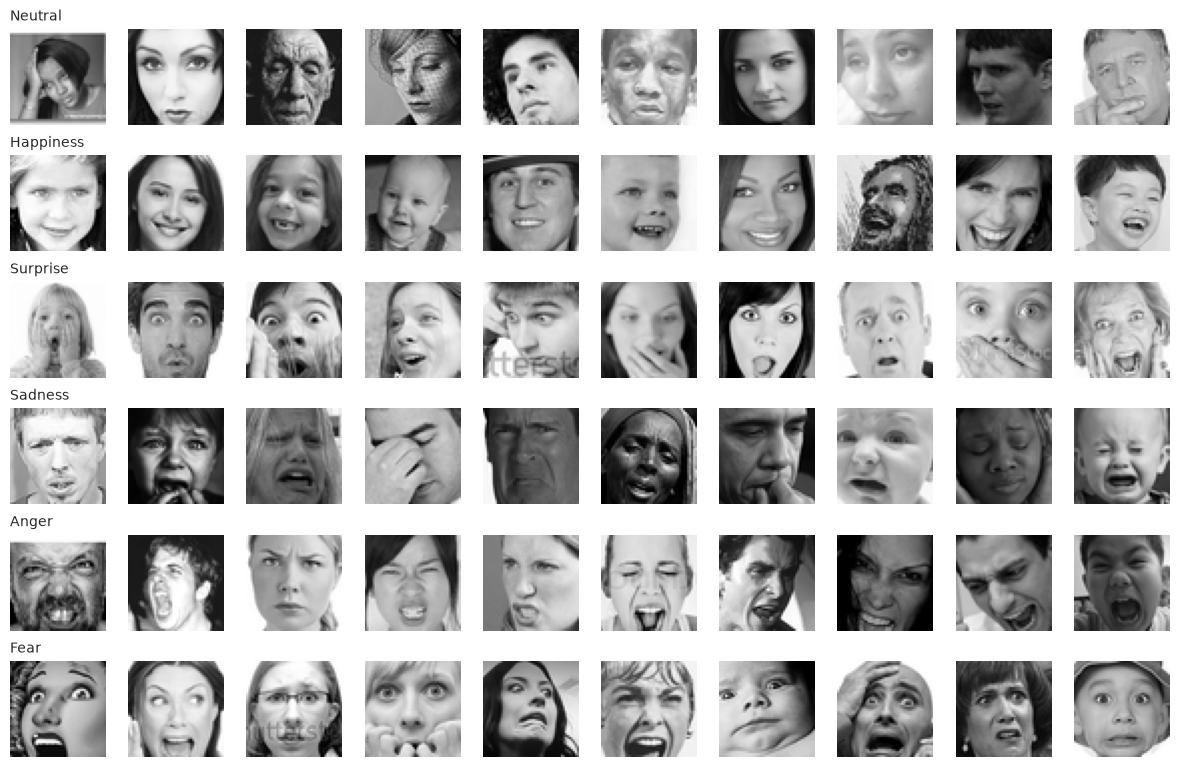

In [8]:
X_train, y_train = data["Train"]
n_cols = 10
fig, axes = plt.subplots(len(CLASSES), n_cols, figsize=(n_cols * 1.2, len(CLASSES) * 1.3))
for c, name in enumerate(CLASSES):
    picks = rng.choice(np.flatnonzero(y_train == c), n_cols, replace=False)
    for ax, i in zip(axes[c], picks):
        ax.imshow(X_train[i], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
    axes[c, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
fig.savefig(FIG / "samples_per_class.png", dpi=150)
plt.show()

Images show great diversity in terms of pose, illumination, age and occlusions (for example, hands, glasses and on-screen text). Some also have poor contrast. Such diversity is a key difficulty in performing FER "in the wild".

### Mean face per class

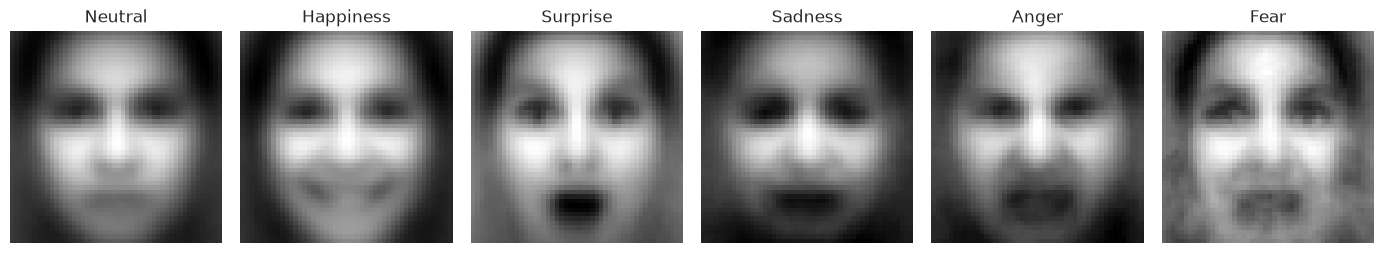

In [9]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 2.8))
for c, (ax, name) in enumerate(zip(axes, CLASSES)):
    ax.imshow(X_train[y_train == c].mean(axis=0), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "mean_faces.png", dpi=150)
plt.show()

Average images already exhibit differences in the mouth and eye regions. Happiness is indicated by an open mouth and smile, while Surprise is indicated by an open mouth and raised eyebrows. Images are roughly aligned and so spatial features such as HOG can be applied.

### Pixel intensities

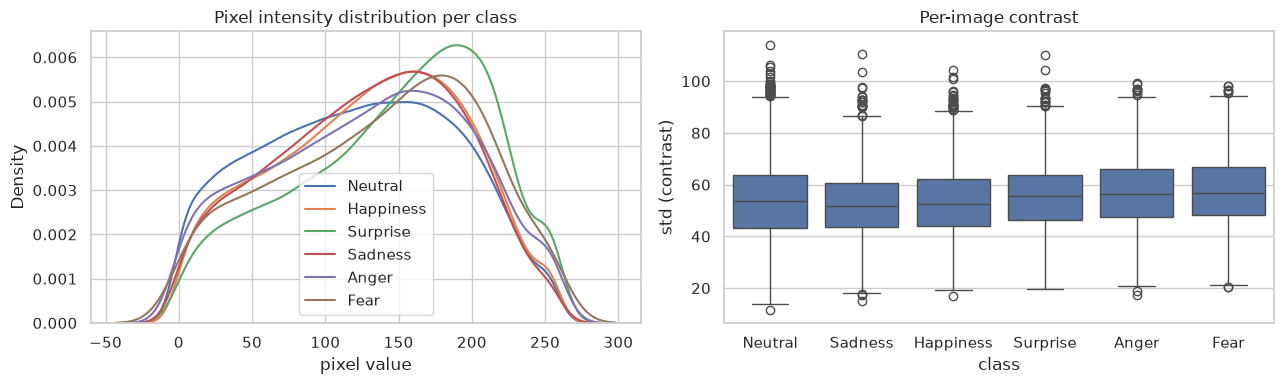

            mean  std (contrast)
class                           
Anger      129.5            57.0
Fear       137.4            57.6
Happiness  130.2            53.1
Neutral    122.0            54.0
Sadness    128.4            52.6
Surprise   146.0            55.5
near-blank images (std < 5): 0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for c, name in enumerate(CLASSES):
    sns.kdeplot(X_train[y_train == c][:, ::4, ::4].ravel(), ax=axes[0], label=name, bw_adjust=2)
axes[0].set_xlabel("pixel value")
axes[0].set_title("Pixel intensity distribution per class")
axes[0].legend()

brightness = pd.DataFrame({"mean": X_train.mean(axis=(1, 2)), "std (contrast)": X_train.std(axis=(1, 2)),
                           "class": np.array(CLASSES)[y_train]})
sns.boxplot(data=brightness, x="class", y="std (contrast)", ax=axes[1])
axes[1].set_title("Per-image contrast")
plt.tight_layout()
fig.savefig(FIG / "intensity_stats.png", dpi=150)
plt.show()

print(brightness.groupby("class")[["mean", "std (contrast)"]].mean().round(1))
print("near-blank images (std < 5):", int((brightness["std (contrast)"] < 5).sum()))

Classes also share similar lightness and contrast properties and so a model cannot distinguish between them based on illumination. (On average, Surprise images are marginally lighter.) Further, none of the images is blank or nearly uniform.

### Do the 48×48 and 224×224 versions show the same faces?

We reduce random 224×224 images to 48×48 and compare them with the 48×48 data.

mean absolute difference: 1.71 gray levels (max 5.14) out of 255


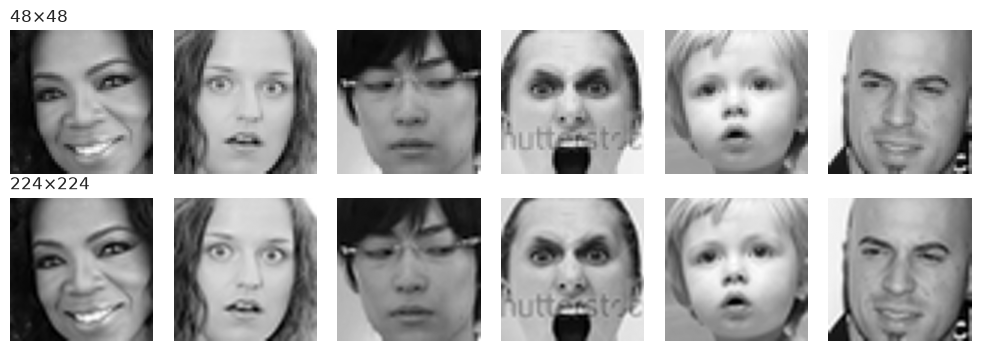

In [11]:
X_test48, _ = data["Test"]
X_test224, _ = load_split("Test", size=224)
idx = rng.choice(len(X_test48), 300, replace=False)
down = np.stack([cv2.resize(X_test224[i], (48, 48), interpolation=cv2.INTER_AREA) for i in idx])
diff = np.abs(down.astype(int) - X_test48[idx].astype(int)).mean(axis=(1, 2))
print(f"mean absolute difference: {diff.mean():.2f} gray levels (max {diff.max():.2f}) out of 255")

fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for k in range(6):
    axes[0, k].imshow(X_test48[idx[k]], cmap="gray")
    axes[1, k].imshow(X_test224[idx[k]], cmap="gray")
    axes[0, k].axis("off")
    axes[1, k].axis("off")
axes[0, 0].set_title("48×48", loc="left")
axes[1, 0].set_title("224×224", loc="left")
plt.tight_layout()
plt.show()
del X_test224

### Exact duplicates

As FER2013 data was obtained by web image searching, we investigate whether images are duplicated, and in particular whether test images are also found in the training data.

In [12]:
def image_hashes(images):
    return np.array([hashlib.md5(img.tobytes()).hexdigest() for img in images])

hashes = {split: image_hashes(X) for split, (X, _) in data.items()}
for split, h in hashes.items():
    print(f"{split:5s}: {len(h) - len(set(h))} duplicate images inside the split")

train_set = set(hashes["Train"])
for split in ("Valid", "Test"):
    overlap = sum(h in train_set for h in hashes[split])
    print(f"{split} images that also appear in Train: {overlap} ({100 * overlap / len(hashes[split]):.2f}%)")

Train: 954 duplicate images inside the split
Valid: 20 duplicate images inside the split
Test : 14 duplicate images inside the split
Valid images that also appear in Train: 222 (7.07%)
Test images that also appear in Train: 229 (7.38%)


Around 7% of the Valid and Test images are byte-identical copies of training images. Further, there are far greater numbers of duplicates within the training data. Occasionally, duplicated images have different labels. Not all classes are equally over-represented in this duplicated data:

In [13]:
X_test, y_test = data["Test"]
in_train = np.isin(hashes["Test"], hashes["Train"])
overlap = pd.DataFrame({
    "test images": np.bincount(y_test, minlength=len(CLASSES)),
    "also in Train": np.bincount(y_test[in_train], minlength=len(CLASSES)),
}, index=CLASSES)
overlap["%"] = (100 * overlap["also in Train"] / overlap["test images"]).round(1)
overlap

,test images,also in Train,%
Neutral,1081,32,3.0
Happiness,891,35,3.9
Surprise,400,105,26.2
Sadness,384,22,5.7
Anger,266,25,9.4
Fear,81,10,12.3


Indeed, a quarter of Test Surprise images are also in the training data. Thus, models which simply memorize training data are favored for this class. Although we retain the official data split to allow comparison with other FERPlus research, all models additionally provide test results for the *clean* test data (that is, test images not found in training data). All the model notebooks find these images in the same way, by comparing the pixel byte values.

## 4. Class weights

All models use identical class weightings, determined solely from the training data. These follow the same equation as scikit-learn's `class_weight="balanced"` functionality; $w_c = N / (K \cdot n_c)$. Fear images have a weight of around 8 and Neutral images of around 0.5. Thus, a model incurs 17× greater cost for incorrectly predicting a Fear image, compared to incorrectly predicting a Neutral image.

In [14]:
# Inverse class frequency weights. Identical to scikit-learn's class_weight="balanced".
weights = len(y_train) / (len(CLASSES) * np.bincount(y_train))
weights_df = pd.DataFrame({"train images": np.bincount(y_train), "weight": weights.round(3)}, index=CLASSES)
(RESULTS_DIR / "class_weights.json").write_text(json.dumps(dict(zip(CLASSES, weights.round(4).tolist())), indent=2))
weights_df

,train images,weight
Neutral,8740,0.473
Happiness,7304,0.566
Surprise,3125,1.322
Sadness,3046,1.356
Anger,2056,2.009
Fear,512,8.067


## Summary

- There are 31,312 images in common data files. Excluding Disgust and Contempt reduces this number to 31,026 (24,783 Train; 3,140 Valid; 3,103 Test) for the 6 classes.
- Both 48×48 and 224×224 data contain identical images in the same sequence (after downsampling, they differ by less than 2 gray levels on average).
- Around 7% (and 26% for Surprise) of Test images are byte-identical to those in the training data. Again, we retain the official data split, but also provide results for the clean Test data.
- Train, Valid and Test all exhibit the same class distributions. Nonetheless, there is still considerable class imbalance (Neutral: 35%; Fear: 2%). Class-weighted loss functions are used to address this. Macro F1 scores are provided.
- Although images are roughly aligned, there is much variation in pose, illumination and occlusions.